<a href="https://colab.research.google.com/github/kattaNagasainikhila-wq/AI-Iris-Classification/blob/main/student_perfomance_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

import urllib.request
import zipfile
import io

# Official UCI dataset ZIP URL
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

print("Downloading Student Performance Dataset...")

response = urllib.request.urlopen(url)

# Extract downloaded ZIP
outer_zip = zipfile.ZipFile(io.BytesIO(response.read()))

# Extract nested ZIP if present
if 'student.zip' in outer_zip.namelist():

    inner_zip = zipfile.ZipFile(
        io.BytesIO(outer_zip.read('student.zip'))
    )

    df = pd.read_csv(
        inner_zip.open('student-mat.csv'),
        sep=';'
    )

else:
    df = pd.read_csv(
        outer_zip.open('student-mat.csv'),
        sep=';'
    )

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:

print("First 10 records:")
display(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


First 10 records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15



Dataset Shape:
(395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [ ]:

print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())


Duplicate records: 0
Shape after removing duplicates: (395, 33)

Missing values after cleaning:
0


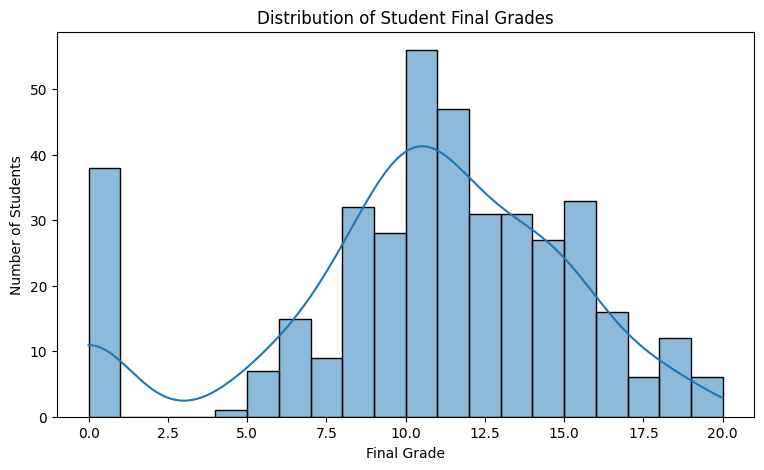

In [ ]:

plt.figure(figsize=(9, 5))

sns.histplot(df['G3'], bins=20, kde=True)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()


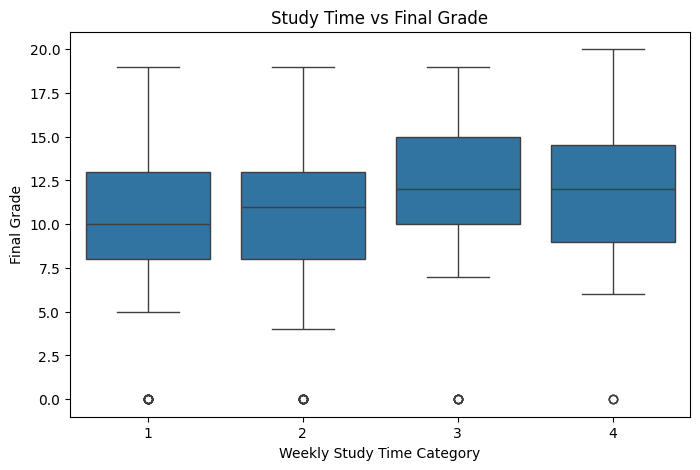

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='studytime', y='G3')

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade")

plt.show()


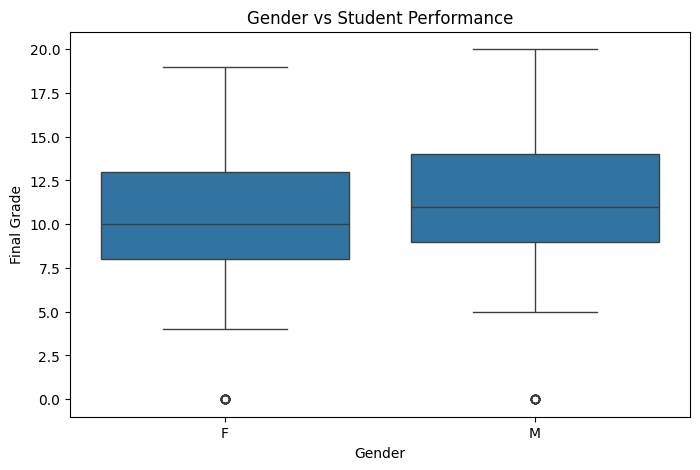

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='sex', y='G3')

plt.title("Gender vs Student Performance")
plt.xlabel("Gender")
plt.ylabel("Final Grade")

plt.show()


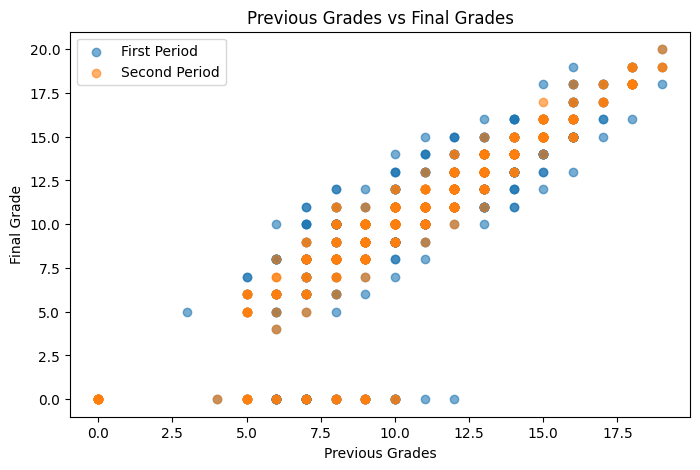

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(df['G1'], df['G3'], label='First Period', alpha=0.6)
plt.scatter(df['G2'], df['G3'], label='Second Period', alpha=0.6)

plt.title("Previous Grades vs Final Grades")
plt.xlabel("Previous Grades")
plt.ylabel("Final Grade")
plt.legend()

plt.show()


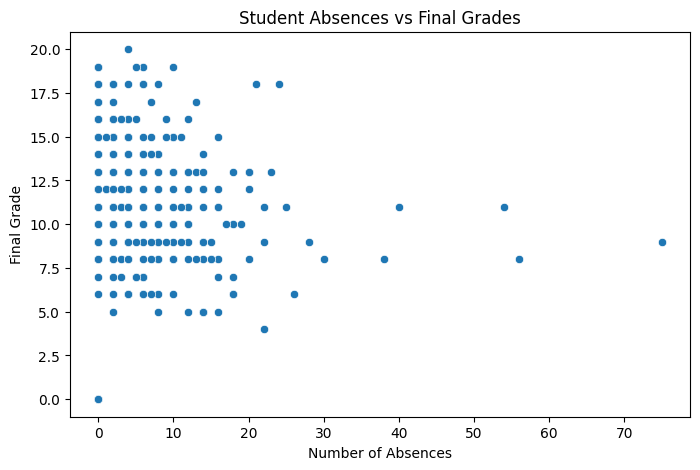

In [ ]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='absences', y='G3')

plt.title("Student Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()


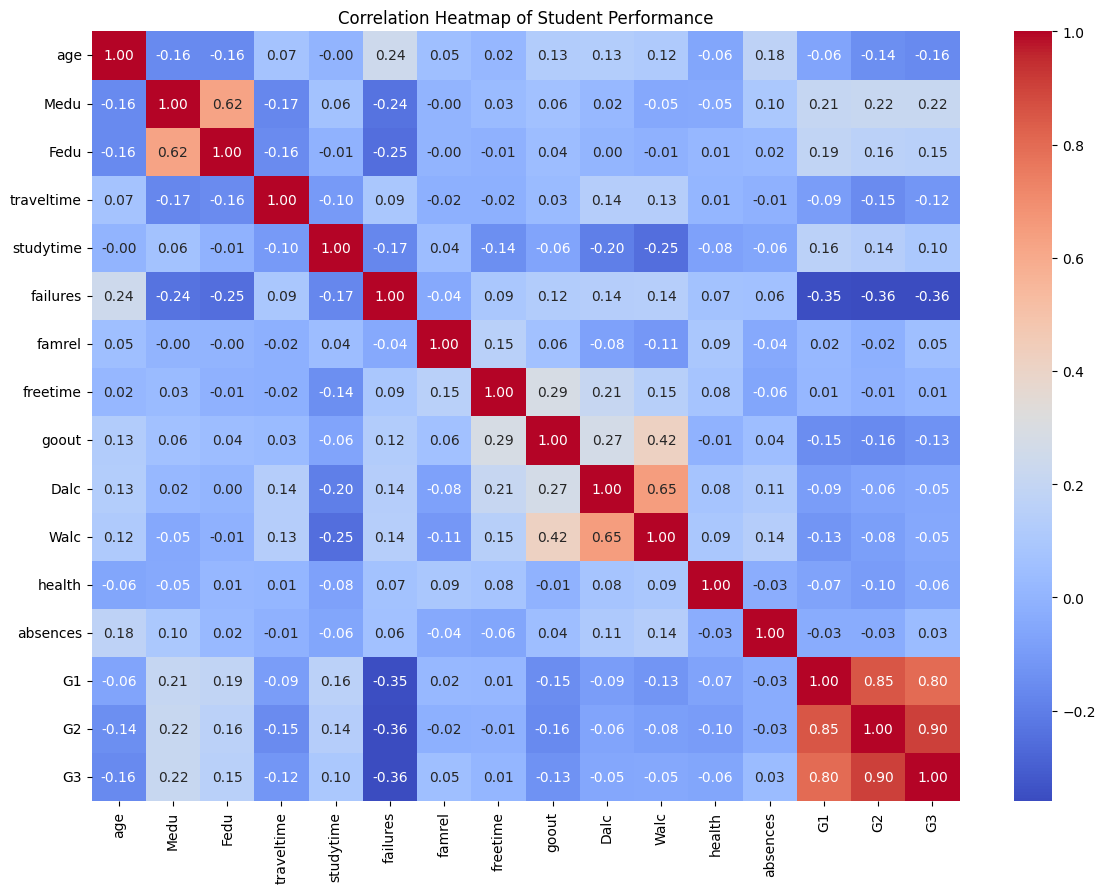

In [ ]:

plt.figure(figsize=(14, 10))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Student Performance")
plt.show()


In [ ]:

X = df.drop('G3', axis=1)
y = df['G3']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget variable:")
print(y.head())


Input features shape: (395, 32)
Target variable shape: (395,)

Target variable:
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64


In [ ]:

numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)


Numerical Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical Features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 316
Testing samples: 79


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns
        )
    ],
    remainder='passthrough'
)

print("Categorical encoding configured successfully!")


Categorical encoding configured successfully!


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print("Linear Regression model created successfully!")


Linear Regression model created successfully!


In [ ]:

model.fit(X_train, y_train)

print("Model training completed successfully!")



Model training completed successfully!


In [ ]:

y_pred = model.predict(X_test)

print("Actual Grades:")
print(y_test.values[:15])

print("\nPredicted Grades:")
print(np.round(y_pred[:15], 2))


Actual Grades:
[10 12  5 10  9 13 18  6  0 14 15  7 15 10 14]

Predicted Grades:
[ 6.   11.53  2.87  8.8   8.55 11.89 19.1   7.17  7.41 12.31 14.5   5.52
 13.64 11.94 14.64]


In [ ]:

results = pd.DataFrame({
    'Actual Grade': y_test.values,
    'Predicted Grade': np.round(y_pred, 2),
    'Error': np.round(y_test.values - y_pred, 2)
})

display(results.head(20))


,Actual Grade,Predicted Grade,Error
0,10,6.00,4.00
1,12,11.53,0.47
2,5,2.87,2.13
3,10,8.80,1.20
4,9,8.55,0.45
5,13,11.89,1.11
6,18,19.10,-1.10
7,6,7.17,-1.17
8,0,7.41,-7.41
9,14,12.31,1.69


In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION MODEL PERFORMANCE")
print("=" * 40)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")


LINEAR REGRESSION MODEL PERFORMANCE
MAE: 1.647
MSE: 5.657
RMSE: 2.378
R2 Score: 0.7241
R2 Percentage: 72.41 %


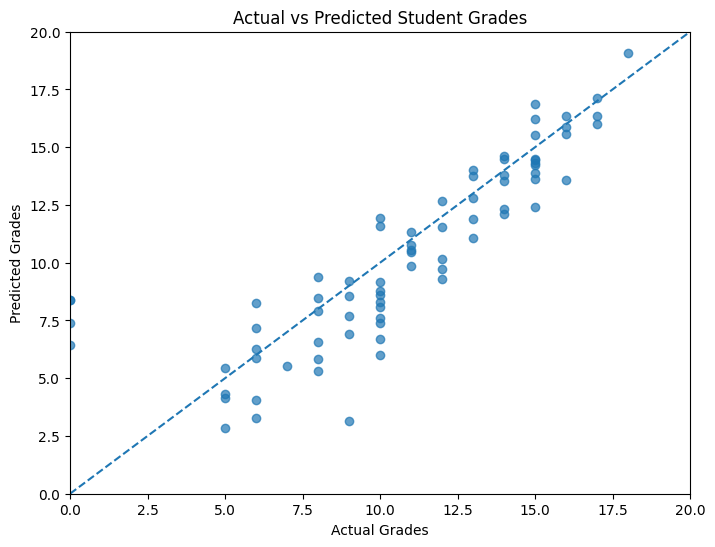

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle='--'
)

plt.title("Actual vs Predicted Student Grades")
plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.show()


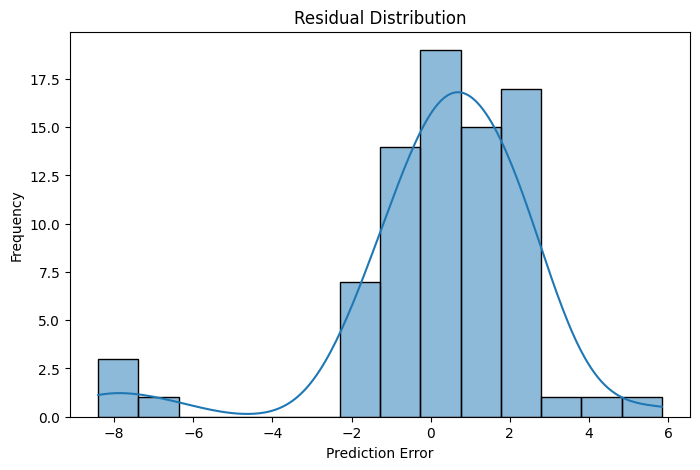

In [ ]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()


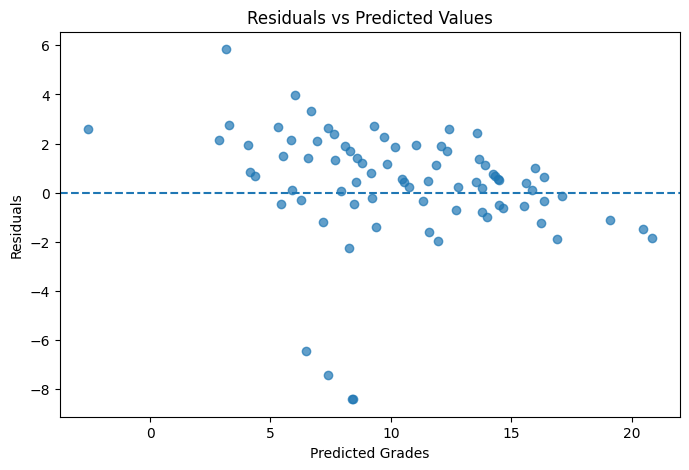

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(y=0, linestyle='--')

plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Grades")
plt.ylabel("Residuals")

plt.show()


In [ ]:

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = model.named_steps[
    'regressor'
].coef_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feature_importance['Absolute_Coefficient'] = (
    feature_importance['Coefficient'].abs()
)

feature_importance = feature_importance.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

display(feature_importance.head(15))


,Feature,Coefficient,Absolute_Coefficient
57,remainder__G2,0.957772,0.957772
21,categorical__reason_home,-0.479745,0.479745
22,categorical__reason_other,0.437128,0.437128
16,categorical__Fjob_health,0.416316,0.416316
28,categorical__schoolsup_yes,0.392826,0.392826
27,categorical__schoolsup_no,-0.392826,0.392826
18,categorical__Fjob_services,-0.359688,0.359688
11,categorical__Mjob_health,-0.332658,0.332658
49,remainder__famrel,0.314962,0.314962
48,remainder__failures,-0.285781,0.285781


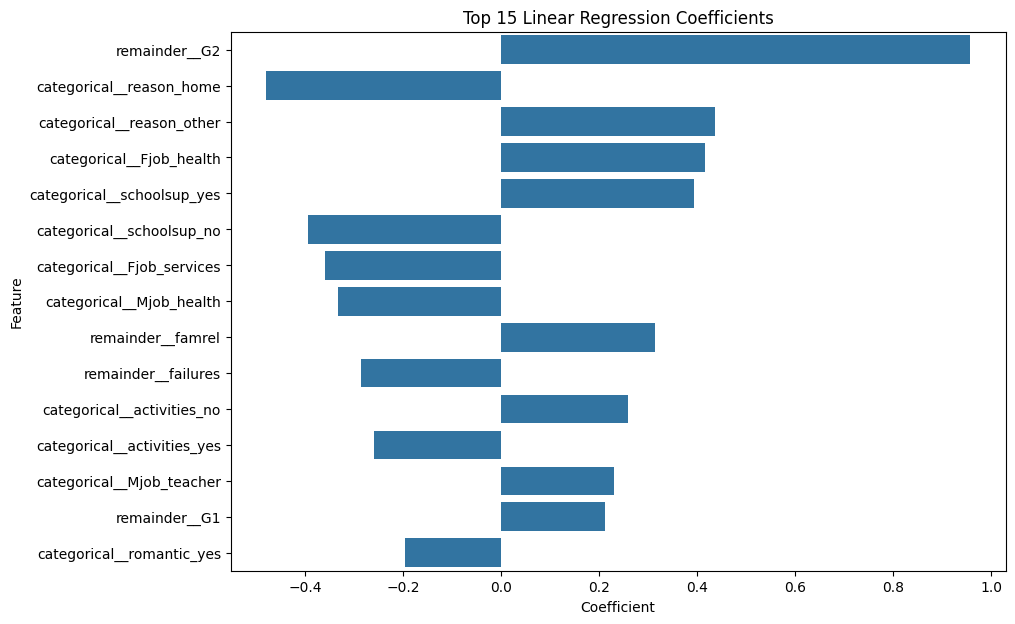

In [ ]:

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Coefficient',
    y='Feature'
)

plt.title("Top 15 Linear Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()


In [ ]:

# Take one student record from testing data
sample_student = X_test.iloc[[0]].copy()

# Change some student details
sample_student.loc[:, 'studytime'] = 3
sample_student.loc[:, 'absences'] = 2
sample_student.loc[:, 'failures'] = 0

# Predict final grade
predicted_grade = model.predict(sample_student)[0]

print("STUDENT PERFORMANCE PREDICTION")
print("=" * 35)

print("Study Time Category: 3")
print("Absences: 2")
print("Previous Failures: 0")

print("\nPredicted Final Grade:",
      round(predicted_grade, 2), "/ 20")


STUDENT PERFORMANCE PREDICTION
Study Time Category: 3
Absences: 2
Previous Failures: 0

Predicted Final Grade: 6.84 / 20


In [ ]:

# Remove previous grades
X_without_grades = df.drop(
    columns=['G1', 'G2', 'G3']
)

y_target = df['G3']

# Split data
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_without_grades,
    y_target,
    test_size=0.20,
    random_state=42
)

# Identify categorical features
cat_cols2 = X_without_grades.select_dtypes(
    include=['object']
).columns.tolist()

# Build preprocessing
preprocessor2 = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            cat_cols2
        )
    ],
    remainder='passthrough'
)

# Build model
model_without_grades = Pipeline([
    ('preprocessor', preprocessor2),
    ('regressor', LinearRegression())
])

# Train
model_without_grades.fit(X_train2, y_train2)

# Predict
pred2 = model_without_grades.predict(X_test2)

# Evaluate
r2_without_grades = r2_score(y_test2, pred2)
mae_without_grades = mean_absolute_error(y_test2, pred2)

print("MODEL WITHOUT PREVIOUS GRADES")
print("R2 Score:", round(r2_without_grades, 4))
print("MAE:", round(mae_without_grades, 3))


MODEL WITHOUT PREVIOUS GRADES
R2 Score: 0.1415
MAE: 3.395


In [ ]:

comparison = pd.DataFrame({
    'Model': [
        'With G1 and G2',
        'Without G1 and G2'
    ],
    'R2 Score': [
        r2,
        r2_without_grades
    ],
    'MAE': [
        mae,
        mae_without_grades
    ]
})

display(comparison)


,Model,R2 Score,MAE
0,With G1 and G2,0.724134,1.646666
1,Without G1 and G2,0.141492,3.395261


In [ ]:

import joblib

# Save full model
joblib.dump(
    model,
    'student_performance_model.pkl'
)

# Save model without previous grades
joblib.dump(
    model_without_grades,
    'student_performance_model_without_G1_G2.pkl'
)

print("Both models saved successfully!")


Both models saved successfully!


In [ ]:

from google.colab import files

files.download('student_performance_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

files.download('student_performance_model_without_G1_G2.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>